# Validate LLMs

This notebook contains code to validate the performance of large language models (LLMs) on annotations of dimensional emotion scores from the EMOBANK dataset. It compares the LLM annotations to those of trained research staff (see Codebook). It includes checks for annotator transitivity, reliability, and explores at which epsilon values each LLM passes the AltTest.

LLMs examined:
- GPT-5.1
- GPT-5-nano
- Claude-Haiku-4.5
- Claude-Sonnet-4.5

In [2]:
import sys
import os
import pandas as pd
import pairadigm as pdm
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import glob
import re

import dotenv

dotenv.load_dotenv(dotenv_path='/Users/mlchrzan/Library/CloudStorage/OneDrive-Personal/Professional/Data Science/Maryland/bechmark analysis pipeline/benchmark-analysis/.env')

/Users/mlchrzan/opt/anaconda3/envs/emopair/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


True

This code pulls together the annotation data from the trained staff. 

In [3]:
# Initialize dataframes for each concept
valence_df = None
arousal_df = None
dominance_df = None

# Get all annotation files
files = glob.glob('Data/human annotations/Completed/pairs_for_human_annotation - A*.xlsx')

# Process each file
for file in files:
    # Extract annotator number from filename
    match = re.search(r'A(\d+)', file)
    annotator_num = match.group(1)
    
    # Read all sheets
    sheets = pd.read_excel(file, sheet_name=None)
    
    # Process each concept sheet
    for sheet_name, df in sheets.items():
        concept = sheet_name.lower()
        
        # Skip if not a concept sheet
        if concept not in ['valence', 'arousal', 'dominance']:
            continue
        
        # Create decision column name
        decision_col = f'A{annotator_num}'
        
        # Rename concept column and map values
        df_copy = df.copy()
        # Make the fifth column name (the prompt given to the annotators) the name of the concept
        df_copy.rename(columns={df_copy.columns[4]: concept}, inplace=True)
        df_copy[decision_col] = df_copy[concept].map({1: 'Text1', 2: 'Text2', 0: 'Tie'})

        # Adjust the Notes column to be a string and rename it with the annotator_num
        if 'Notes' in df_copy.columns:
            df_copy['Notes'] = df_copy['Notes'].astype(str)
            df_copy['Notes'] = df_copy['Notes'].replace('nan', '')
            df_copy.rename(columns={'Notes': f'Notes_A{annotator_num}'}, inplace=True)
            notes_col = f"Notes_A{annotator_num}"
        
        # Keep only necessary columns
        base_cols = ['item1', 'item2', 'text1', 'text2']
        df_copy = df_copy[base_cols + [decision_col] + [notes_col]]
        
        # Merge with appropriate concept dataframe
        if concept == 'valence':
            if valence_df is None:
                valence_df = df_copy
            else:
                valence_df = valence_df.merge(df_copy, on=base_cols, how='outer')
        elif concept == 'arousal':
            if arousal_df is None:
                arousal_df = df_copy
            else:
                arousal_df = arousal_df.merge(df_copy, on=base_cols, how='outer')
        elif concept == 'dominance':
            if dominance_df is None:
                dominance_df = df_copy
            else:
                dominance_df = dominance_df.merge(df_copy, on=base_cols, how='outer')

print(f"Valence annotations: {valence_df.shape}")
print(f"Arousal annotations: {arousal_df.shape}")
print(f"Dominance annotations: {dominance_df.shape}")

Valence annotations: (293, 12)
Arousal annotations: (293, 12)
Dominance annotations: (293, 12)


In [10]:
# Load CGCOT Prompts
with open('Data/cgcot_prompts/valence.txt', 'r') as file:
    val_prompts = file.read().splitlines()

with open('Data/cgcot_prompts/arousal.txt', 'r') as file:
    aro_prompts = file.read().splitlines()

with open('Data/cgcot_prompts/dominance.txt', 'r') as file:
    dom_prompts = file.read().splitlines()

# Prep pairadigms

In [14]:
# Initialize Pairadigm objects
p_val = pdm.Pairadigm(
    data=valence_df,
    item_id_cols=['item1', 'item2'],
    item_text_cols=['text1', 'text2'],
    paired=True,
    annotated=True,
    annotator_cols=[col for col in valence_df.columns if col.startswith('A')],
    cgcot_prompts=val_prompts,
    model_name=["gpt-5.1", 
                'gpt-5-nano',
                "claude-sonnet-4-5",
                'claude-haiku-4-5'],
    api_key=[os.getenv('OPENAI_API_KEY'), 
             os.getenv('OPENAI_API_KEY'),
             os.getenv('ANTHROPIC_API_KEY'),
             os.getenv('ANTHROPIC_API_KEY')],
    base_url=["https://us.api.openai.com/v1", 
              "https://us.api.openai.com/v1",
              None, None],
    target_concept='valence'
)

p_aro = pdm.Pairadigm(
    data=arousal_df,
    item_id_cols=['item1', 'item2'],
    item_text_cols=['text1', 'text2'],
    paired=True,
    annotated=True,
    annotator_cols=[col for col in arousal_df.columns if col.startswith('A')],
    cgcot_prompts=aro_prompts,
    model_name=["gpt-5.1",
                'gpt-5-nano', 
                "claude-sonnet-4-5",
                'claude-haiku-4-5'],
    api_key=[os.getenv('OPENAI_API_KEY'), 
             os.getenv('OPENAI_API_KEY'),
             os.getenv('ANTHROPIC_API_KEY'),
             os.getenv('ANTHROPIC_API_KEY')],
    base_url=["https://us.api.openai.com/v1", 
              "https://us.api.openai.com/v1",
              None, None],
    target_concept='arousal'
)

p_dom = pdm.Pairadigm(
    data=dominance_df,
    item_id_cols=['item1', 'item2'],
    item_text_cols=['text1', 'text2'],
    paired=True,
    annotated=True,
    annotator_cols=[col for col in dominance_df.columns if col.startswith('A')],
    cgcot_prompts=dom_prompts,
    model_name=["gpt-5.1", 
                'gpt-5-nano',
                "claude-sonnet-4-5",
                'claude-haiku-4-5'],
    api_key=[os.getenv('OPENAI_API_KEY'), 
             os.getenv('OPENAI_API_KEY'),
             os.getenv('ANTHROPIC_API_KEY'),
             os.getenv('ANTHROPIC_API_KEY')],
    base_url=["https://us.api.openai.com/v1", 
              "https://us.api.openai.com/v1",
              None, None],
    target_concept='dominance'
)

In [17]:
p_dom.get_clients_info()

,index,model_name,provider
0,0,gpt-5.1,openai
1,1,gpt-5-nano,openai
2,2,claude-sonnet-4-5,anthropic
3,3,claude-haiku-4-5,anthropic


# Build pairadigms

In [ ]:
for p in [p_val, p_aro, p_dom]:
    p.generate_breakdowns_from_paired()
# run time: 20 minutes

In [ ]:
for p in [p_val, p_aro, p_dom]:
    p.generate_pairwise_annotations(allow_ties=True)
# run time: 30 minutes

[gpt-5.1] Completed 50/293 comparisons
[gpt-5.1] Completed 100/293 comparisons
[gpt-5.1] Completed 150/293 comparisons
[gpt-5.1] Completed 200/293 comparisons
[gpt-5.1] Completed 250/293 comparisons
[gpt-5-nano] Completed 50/293 comparisons
[gpt-5-nano] Completed 100/293 comparisons
[gpt-5-nano] Completed 150/293 comparisons
[gpt-5-nano] Completed 200/293 comparisons
[gpt-5-nano] Completed 250/293 comparisons
[claude-sonnet-4-5] Completed 50/293 comparisons
[claude-sonnet-4-5] Completed 100/293 comparisons
[claude-sonnet-4-5] Completed 150/293 comparisons
[claude-sonnet-4-5] Completed 200/293 comparisons
[claude-sonnet-4-5] Completed 250/293 comparisons
[claude-haiku-4-5] Completed 50/293 comparisons
[claude-haiku-4-5] Completed 100/293 comparisons
[claude-haiku-4-5] Completed 150/293 comparisons
[claude-haiku-4-5] Completed 200/293 comparisons
[claude-haiku-4-5] Completed 250/293 comparisons
[gpt-5.1] Completed 50/293 comparisons
[gpt-5.1] Completed 100/293 comparisons
[gpt-5.1] Compl

# Validation

## IRR

In [82]:
for p in [p_val, p_aro, p_dom]:
    p.irr()


INTER-RATER RELIABILITY RESULTS

HUMAN ANNOTATORS:
  Method: Krippendorff
  Score: 0.886
  Interpretation: Almost Perfect
  Annotators: 4
  Items: 293

LLM ANNOTATORS:
  Method: Krippendorff
  Score: 0.894
  Interpretation: Almost Perfect
  Annotators: 8
  Items: 293

ALL ANNOTATORS:
  Method: Krippendorff
  Score: 0.853
  Interpretation: Almost Perfect
  Annotators: 12
  Items: 293


INTER-RATER RELIABILITY RESULTS

HUMAN ANNOTATORS:
  Method: Krippendorff
  Score: 0.876
  Interpretation: Almost Perfect
  Annotators: 4
  Items: 293

LLM ANNOTATORS:
  Method: Krippendorff
  Score: 0.906
  Interpretation: Almost Perfect
  Annotators: 4
  Items: 293

ALL ANNOTATORS:
  Method: Krippendorff
  Score: 0.866
  Interpretation: Almost Perfect
  Annotators: 8
  Items: 293


INTER-RATER RELIABILITY RESULTS

HUMAN ANNOTATORS:
  Method: Krippendorff
  Score: 0.849
  Interpretation: Almost Perfect
  Annotators: 4
  Items: 293

LLM ANNOTATORS:
  Method: Krippendorff
  Score: 0.884
  Interpretation: 

## Transitivity

In [83]:
for p in [p_val, p_aro, p_dom]:
    display(p.check_transitivity())

{'A1': (0.8291457286432161, 34, 199),
 'A3': (0.9195979899497487, 16, 199),
 'A2': (0.9899497487437185, 2, 199),
 'A4': (0.9547738693467337, 9, 199),
 'decision_gpt-5.1': (0.9849246231155779, 3, 199),
 'decision_gpt-5-nano': (0.8473282442748091, 20, 131),
 'decision_claude-sonnet-4-5': (0.8743718592964824, 25, 199),
 'decision_claude-haiku-4-5': (0.9748743718592965, 5, 199)}

{'A1': (0.8542713567839196, 29, 199),
 'A3': (0.8391959798994975, 32, 199),
 'A2': (0.9597989949748744, 8, 199),
 'A4': (0.9447236180904522, 11, 199),
 'decision_gpt-5.1': (0.9296482412060302, 14, 199),
 'decision_gpt-5-nano': (0.943502824858757, 10, 177),
 'decision_claude-sonnet-4-5': (0.8994974874371859, 20, 199),
 'decision_claude-haiku-4-5': (0.9698492462311558, 6, 199)}

{'A1': (0.8743718592964824, 25, 199),
 'A3': (0.8994974874371859, 20, 199),
 'A2': (0.9547738693467337, 9, 199),
 'A4': (0.8442211055276382, 31, 199),
 'decision_gpt-5.1': (0.9899497487437185, 2, 199),
 'decision_gpt-5-nano': (0.9230769230769231, 11, 143),
 'decision_claude-sonnet-4-5': (0.9748743718592965, 5, 199),
 'decision_claude-haiku-4-5': (0.9195979899497487, 16, 199)}

## AltTest

Testing 36 epsilon values from -0.1 to 0.25...
Testing all 4 LLM decision columns: ['decision_gpt-5.1', 'decision_gpt-5-nano', 'decision_claude-sonnet-4-5', 'decision_claude-haiku-4-5']
Using LLM decision column: decision_gpt-5.1
Using LLM decision column: decision_gpt-5.1

ALT-TEST RESULTS - GPT-5.1
Winning Rate (ω): 0.000
Advantage Probability: 0.660
Tested against 4 human annotators

Using LLM decision column: decision_gpt-5-nano

ALT-TEST RESULTS - GPT-5-NANO
Winning Rate (ω): 0.000
Advantage Probability: 0.670
Tested against 4 human annotators

Using LLM decision column: decision_claude-sonnet-4-5

ALT-TEST RESULTS - CLAUDE-SONNET-4-5
Winning Rate (ω): 0.000
Advantage Probability: 0.590
Tested against 4 human annotators

Using LLM decision column: decision_claude-haiku-4-5

ALT-TEST RESULTS - CLAUDE-HAIKU-4-5
Winning Rate (ω): 0.000
Advantage Probability: 0.635
Tested against 4 human annotators

Testing all 4 LLM decision columns: ['decision_gpt-5.1', 'decision_gpt-5-nano', 'decis

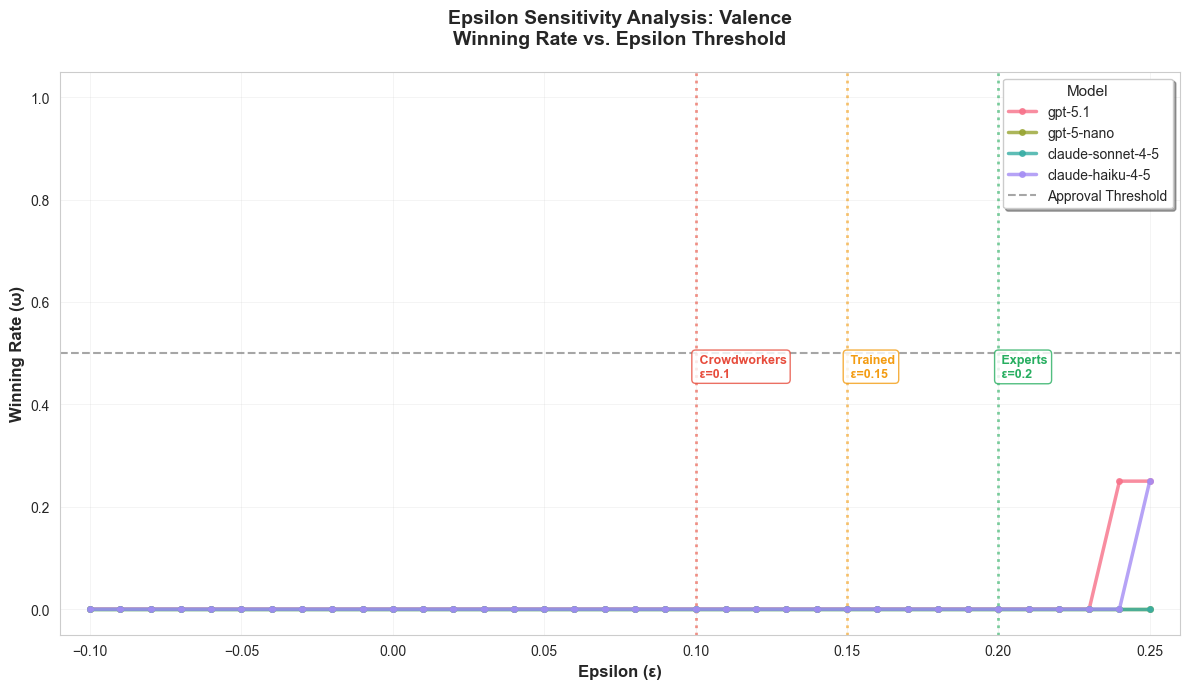

In [85]:
epsilon_val = p_val.plot_epsilon_sensitivity(return_data=True)
epsilon_val = pd.DataFrame(epsilon_val[1])
epsilon_val['construct'] = 'valence'

Testing 36 epsilon values from -0.1 to 0.25...
Testing all 4 LLM decision columns: ['decision_gpt-5.1', 'decision_gpt-5-nano', 'decision_claude-sonnet-4-5', 'decision_claude-haiku-4-5']
Using LLM decision column: decision_gpt-5.1
Using LLM decision column: decision_gpt-5.1

ALT-TEST RESULTS - GPT-5.1
Winning Rate (ω): 0.000
Advantage Probability: 0.840
Tested against 4 human annotators

Using LLM decision column: decision_gpt-5-nano
[decision_gpt-5-nano] Dropped 1 instances with less than 2 annotators.

ALT-TEST RESULTS - GPT-5-NANO
Winning Rate (ω): 0.000
Advantage Probability: 0.821
Tested against 4 human annotators

Using LLM decision column: decision_claude-sonnet-4-5

ALT-TEST RESULTS - CLAUDE-SONNET-4-5
Winning Rate (ω): 0.000
Advantage Probability: 0.765
Tested against 4 human annotators

Using LLM decision column: decision_claude-haiku-4-5

ALT-TEST RESULTS - CLAUDE-HAIKU-4-5
Winning Rate (ω): 0.000
Advantage Probability: 0.630
Tested against 4 human annotators

Testing all 4 L

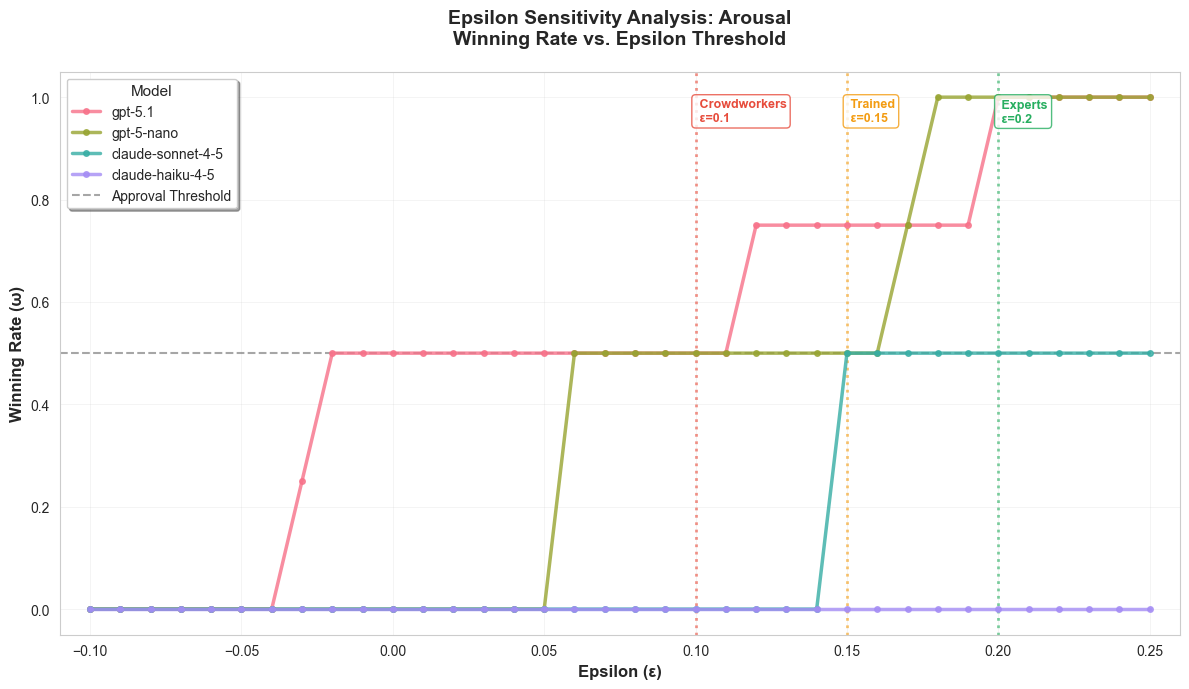

In [60]:
epsilon_aro = p_aro.plot_epsilon_sensitivity(return_data=True)
epsilon_aro = pd.DataFrame(epsilon_aro[1])
epsilon_aro['construct'] = 'arousal'

Testing 36 epsilon values from -0.1 to 0.25...
Testing all 4 LLM decision columns: ['decision_gpt-5.1', 'decision_gpt-5-nano', 'decision_claude-sonnet-4-5', 'decision_claude-haiku-4-5']
Using LLM decision column: decision_gpt-5.1
Using LLM decision column: decision_gpt-5.1

ALT-TEST RESULTS - GPT-5.1
Winning Rate (ω): 0.000
Advantage Probability: 0.780
Tested against 4 human annotators

Using LLM decision column: decision_gpt-5-nano

ALT-TEST RESULTS - GPT-5-NANO
Winning Rate (ω): 0.000
Advantage Probability: 0.810
Tested against 4 human annotators

Using LLM decision column: decision_claude-sonnet-4-5

ALT-TEST RESULTS - CLAUDE-SONNET-4-5
Winning Rate (ω): 0.000
Advantage Probability: 0.775
Tested against 4 human annotators

Using LLM decision column: decision_claude-haiku-4-5

ALT-TEST RESULTS - CLAUDE-HAIKU-4-5
Winning Rate (ω): 0.000
Advantage Probability: 0.790
Tested against 4 human annotators

Testing all 4 LLM decision columns: ['decision_gpt-5.1', 'decision_gpt-5-nano', 'decis

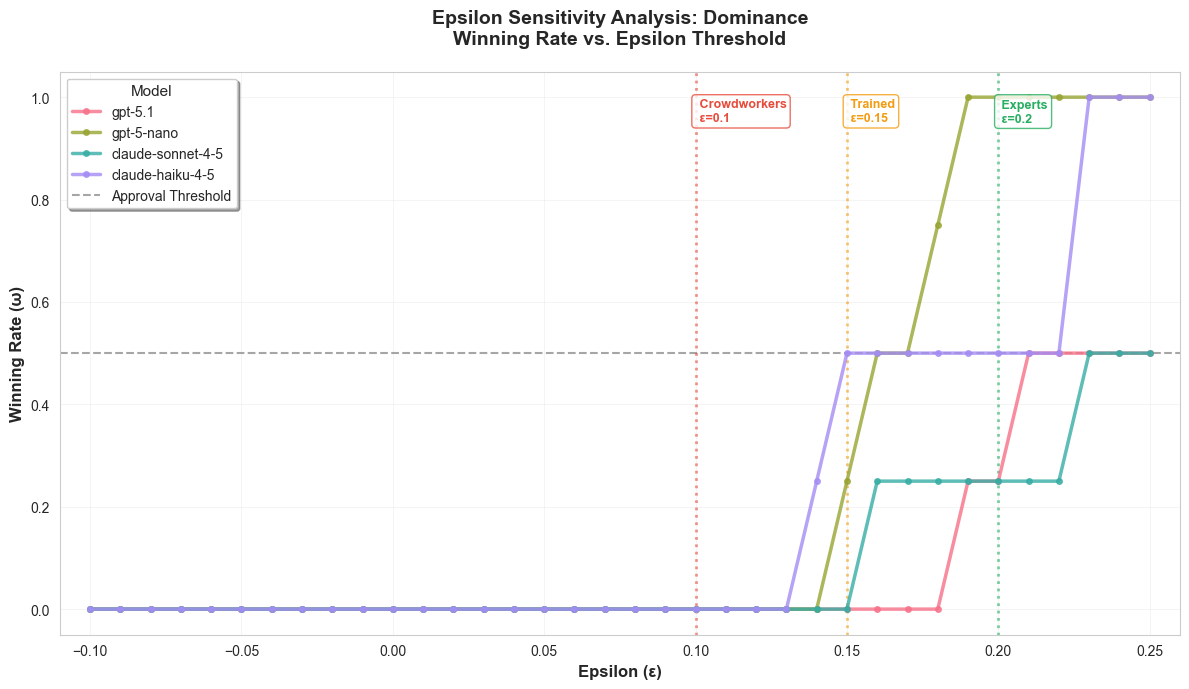

In [61]:
epsilon_dom = p_dom.plot_epsilon_sensitivity(return_data=True)
epsilon_dom = pd.DataFrame(epsilon_dom[1])
epsilon_dom['construct'] = 'dominance'

In [86]:
epsilon_df = pd.concat([epsilon_val, epsilon_aro, epsilon_dom], axis=0)
epsilon_df

,epsilon,winning_rate,advantage_prob,model,construct
0,-0.10,0.0,0.660,gpt-5.1,valence
1,-0.10,0.0,0.670,gpt-5-nano,valence
2,-0.10,0.0,0.590,claude-sonnet-4-5,valence
3,-0.10,0.0,0.635,claude-haiku-4-5,valence
4,-0.09,0.0,0.660,gpt-5.1,valence
...,...,...,...,...,...
139,0.24,1.0,0.790,claude-haiku-4-5,dominance
140,0.25,0.5,0.780,gpt-5.1,dominance
141,0.25,1.0,0.810,gpt-5-nano,dominance
142,0.25,0.5,0.775,claude-sonnet-4-5,dominance


In [ ]:
# Get the advantage probability for each model and construct
ad_prob_df = epsilon_df[['advantage_prob', 'model', 'construct']].drop_duplicates()
ad_prob_df

,advantage_prob,model,construct
0,0.660000,gpt-5.1,valence
1,0.670000,gpt-5-nano,valence
2,0.590000,claude-sonnet-4-5,valence
3,0.635000,claude-haiku-4-5,valence
0,0.840000,gpt-5.1,arousal
1,0.821429,gpt-5-nano,arousal
2,0.765000,claude-sonnet-4-5,arousal
3,0.630000,claude-haiku-4-5,arousal
0,0.780000,gpt-5.1,dominance
1,0.810000,gpt-5-nano,dominance


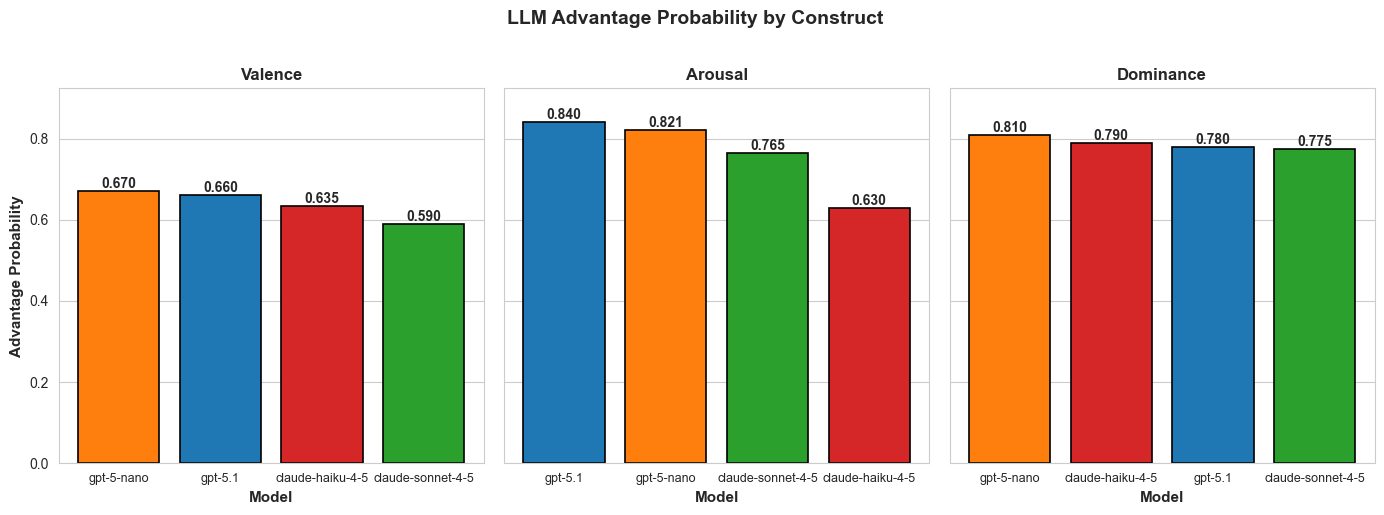

In [88]:
import matplotlib.pyplot as plt
import seaborn as sns

# Define a consistent color palette for models
model_colors = {
    'gpt-5.1': '#1f77b4',
    'gpt-5-nano': '#ff7f0e',
    'claude-sonnet-4-5': '#2ca02c',
    'claude-haiku-4-5': '#d62728'
}

# Create faceted bar plot
fig, axes = plt.subplots(1, 3, figsize=(14, 5), sharey=True)
constructs = ['valence', 'arousal', 'dominance']

for idx, (ax, construct) in enumerate(zip(axes, constructs)):
    # Filter data for this construct
    construct_data = ad_prob_df[ad_prob_df['construct'] == construct].sort_values('advantage_prob', ascending=False)
    
    # Map colors based on model
    colors = [model_colors.get(model, '#808080') for model in construct_data['model']]
    
    # Create bar plot
    bars = ax.bar(construct_data['model'], construct_data['advantage_prob'], 
                   color=colors, 
                   edgecolor='black', linewidth=1.2)
    
    # Add value labels on bars
    for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height,
                f'{height:.3f}',
                ha='center', va='bottom', fontsize=10, fontweight='bold')
    
    # Formatting
    ax.set_title(construct.capitalize(), fontsize=12, fontweight='bold')
    ax.set_xlabel('Model', fontsize=11, fontweight='bold')
    if idx == 0:
        ax.set_ylabel('Advantage Probability', fontsize=11, fontweight='bold')
    ax.set_ylim(0, max(ad_prob_df['advantage_prob']) * 1.1)
    ax.tick_params(axis='x', 
                   #rotation=45, 
                   labelsize=9)
    ax.grid(axis='x', alpha=0, linestyle='--')
    

plt.suptitle('LLM Advantage Probability by Construct', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

## Dawid-Skene (experimental)

In [89]:
p_val.dawid_skene_annotator_ranking(random_seed=42)

Ranking 8 annotators across 293 instances...
Dawid-Skene converged at iteration 44

DAWID-SKENE ANNOTATOR RANKING
Converged at iteration: 44

Top 5 Most Reliable Annotators:
   rank                   annotator  reliability   type
0     1                          A3     0.951901  Human
1     2                          A2     0.899174  Human
2     3                          A4     0.819628  Human
3     4                          A1     0.794224  Human
4     5  decision_claude-sonnet-4-5     0.708560    LLM




,annotator,reliability,type,rank
0,A3,0.951901,Human,1
1,A2,0.899174,Human,2
2,A4,0.819628,Human,3
3,A1,0.794224,Human,4
4,decision_claude-sonnet-4-5,0.708560,LLM,5
5,decision_gpt-5.1,0.691080,LLM,6
6,decision_claude-haiku-4-5,0.690223,LLM,7
7,decision_gpt-5-nano,0.686151,LLM,8


In [39]:
p_aro.dawid_skene_annotator_ranking(random_seed=42)

Ranking 8 annotators across 293 instances...
Dawid-Skene converged at iteration 26

DAWID-SKENE ANNOTATOR RANKING
Converged at iteration: 26

Top 5 Most Reliable Annotators:
   rank                   annotator  reliability   type
0     1         decision_gpt-5-nano     0.967858    LLM
1     2  decision_claude-sonnet-4-5     0.940686    LLM
2     3            decision_gpt-5.1     0.940486    LLM
3     4                          A3     0.913330  Human
4     5                          A2     0.877920  Human




,annotator,reliability,type,rank
0,decision_gpt-5-nano,0.967858,LLM,1
1,decision_claude-sonnet-4-5,0.940686,LLM,2
2,decision_gpt-5.1,0.940486,LLM,3
3,A3,0.913330,Human,4
4,A2,0.877920,Human,5
5,decision_claude-haiku-4-5,0.836406,LLM,6
6,A4,0.741335,Human,7
7,A1,0.696044,Human,8


In [40]:
p_dom.dawid_skene_annotator_ranking(random_seed=42)

Ranking 8 annotators across 293 instances...
Dawid-Skene converged at iteration 45

DAWID-SKENE ANNOTATOR RANKING
Converged at iteration: 45

Top 5 Most Reliable Annotators:
   rank                   annotator  reliability   type
0     1  decision_claude-sonnet-4-5     0.863831    LLM
1     2         decision_gpt-5-nano     0.849023    LLM
2     3   decision_claude-haiku-4-5     0.824090    LLM
3     4                          A3     0.809395  Human
4     5            decision_gpt-5.1     0.767276    LLM




,annotator,reliability,type,rank
0,decision_claude-sonnet-4-5,0.863831,LLM,1
1,decision_gpt-5-nano,0.849023,LLM,2
2,decision_claude-haiku-4-5,0.824090,LLM,3
3,A3,0.809395,Human,4
4,decision_gpt-5.1,0.767276,LLM,5
5,A2,0.761905,Human,6
6,A4,0.700411,Human,7
7,A1,0.605240,Human,8


# Save pairadigms

In [90]:
today = pd.Timestamp.now().strftime('%m-%d-%y')
p_val.save(f'Results/pairadigms/valence_pairadigm_{today}.pkl')
p_aro.save(f'Results/pairadigms/arousal_pairadigm_{today}.pkl')
p_dom.save(f'Results/pairadigms/dominance_pairadigm_{today}.pkl')

Pairadigm object saved successfully to: Results/pairadigms/valence_pairadigm_12-16-25.pkl
Pairadigm object saved successfully to: Results/pairadigms/arousal_pairadigm_12-16-25.pkl
Pairadigm object saved successfully to: Results/pairadigms/dominance_pairadigm_12-16-25.pkl


In [91]:
today = pd.Timestamp.now().strftime('%m-%d-%y')
# Save pairwise results to CSV
for p in [p_val, p_aro, p_dom]:
    paired_results = p.pairwise_df
    paired_results.to_csv(f'Results/paired_results/{p.target_concept}_paired_results_{today}.csv', index=False)

# Valence AltTest Failure Exploration

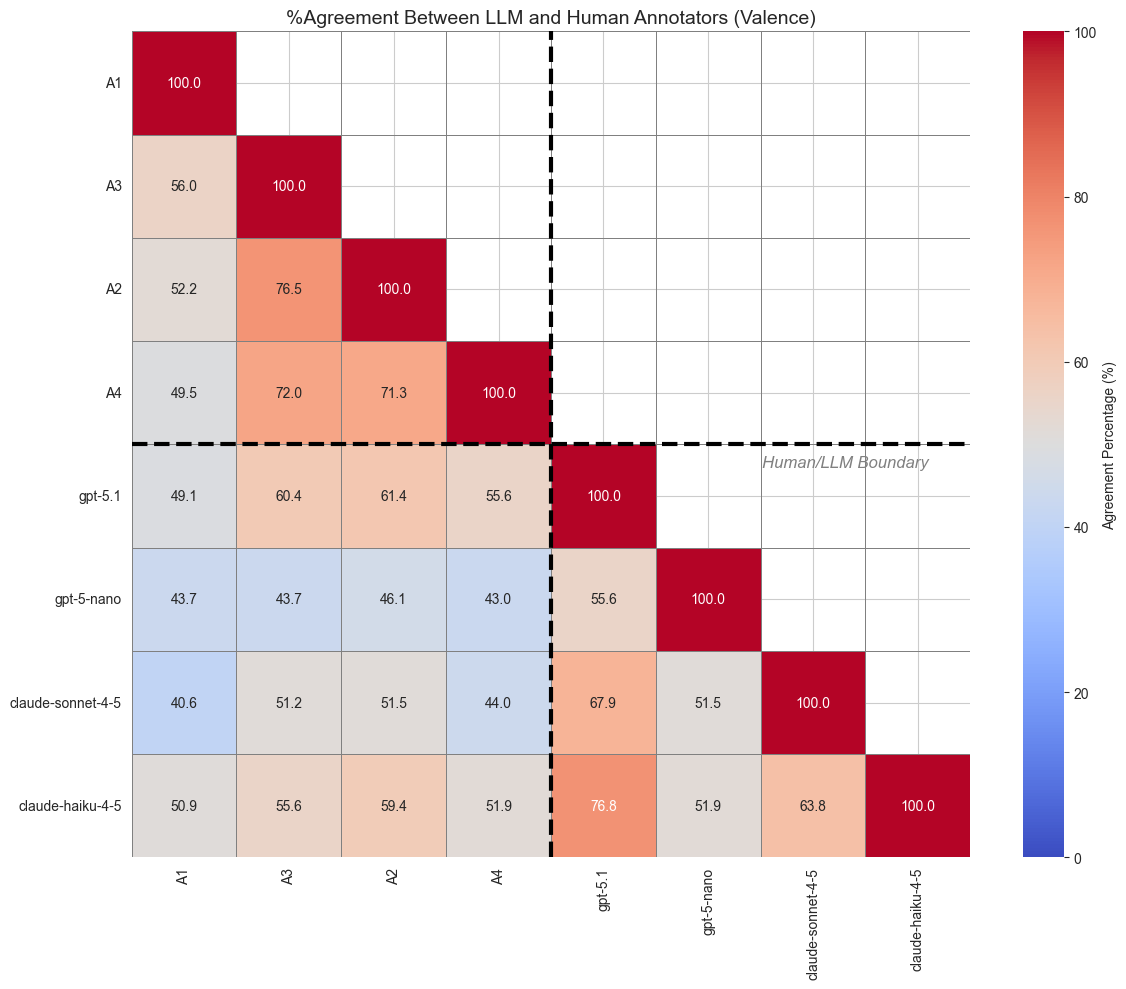

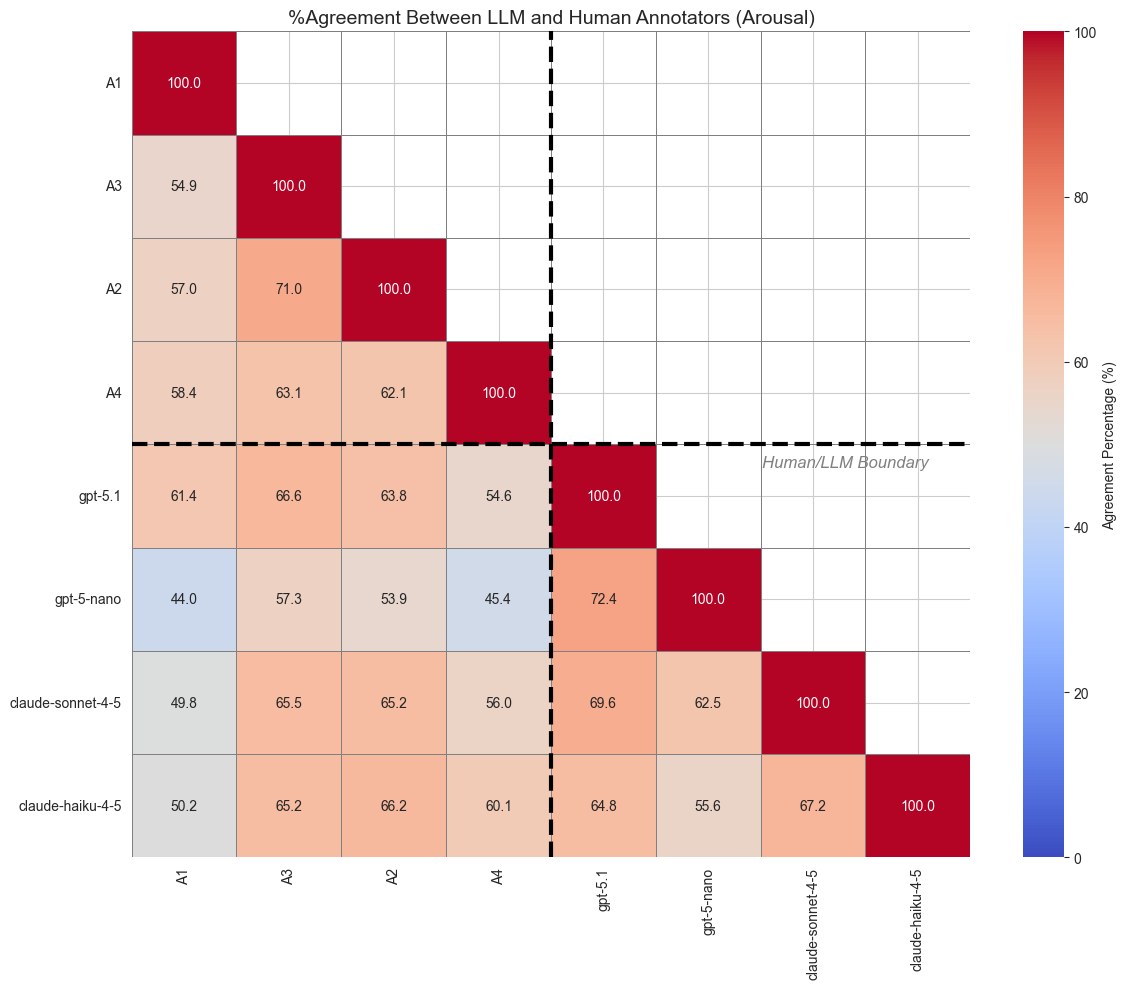

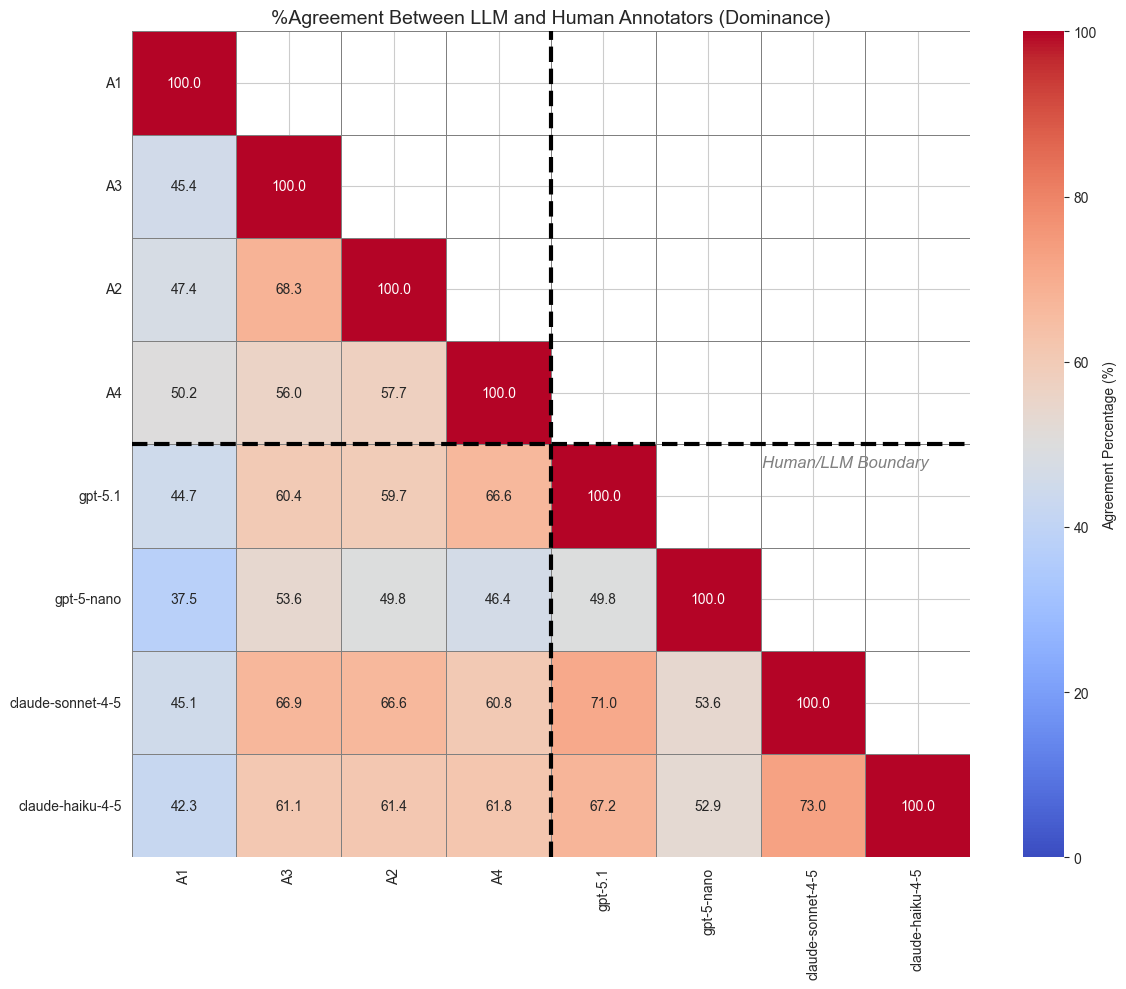

In [119]:
# Define human and LLM annotators, then create agreement heatmaps
for p in [p_val, p_aro, p_dom]:
    human_annotators = [col for col in p.pairwise_df.columns if col.startswith('A')]
    llm_annotators = [col for col in p.pairwise_df.columns if col.startswith('decision')]
    all_annotators = human_annotators + llm_annotators
    
    # Initialize a matrix to store agreement percentages
    agreement_matrix = np.zeros((len(all_annotators), len(all_annotators)))
    
    # Calculate agreement percentages
    for i, llm_col in enumerate(all_annotators):
        for j, human_col in enumerate(all_annotators):
            matches = (p.pairwise_df[llm_col] == p.pairwise_df[human_col]).sum()
            total = len(p.pairwise_df)
            agreement_pct = (matches / total) * 100
            agreement_matrix[i, j] = agreement_pct
    
    # Create clean labels by removing "decision_" prefix
    clean_labels = [col.replace('decision_', '') for col in all_annotators]
    
    # Create a DataFrame for better labeling
    agreement_df = pd.DataFrame(
        agreement_matrix,
        index=clean_labels,
        columns=clean_labels
    )
    
    # Create a mask for the upper triangle
    mask = np.triu(np.ones_like(agreement_df, dtype=bool), k=1)
    
    # Plot the heatmap
    plt.figure(figsize=(12, 10))
    ax = sns.heatmap(
        agreement_df,
        annot=True,
        fmt='.1f',
        cmap='coolwarm',
        vmin=0,
        vmax=100,
        cbar_kws={'label': 'Agreement Percentage (%)'},
        linewidths=0.5,
        linecolor='gray',
        mask=mask
    )
    
    # Add a bold dashed line to separate humans from LLMs
    num_humans = len(human_annotators)
    ax.axhline(y=num_humans, color='black', linewidth=3, linestyle='--')
    ax.axvline(x=num_humans, color='black', linewidth=3, linestyle='--')
    
    # Add italicized text label
    ax.text(len(clean_labels) * 0.95, num_humans + 0.25, 'Human/LLM Boundary', 
            fontsize=12, style='italic', color='gray', ha='right', va='bottom')
    
    plt.title(f'%Agreement Between LLM and Human Annotators ({p.target_concept.capitalize()})', fontsize=14)
    plt.tight_layout()
    plt.show()

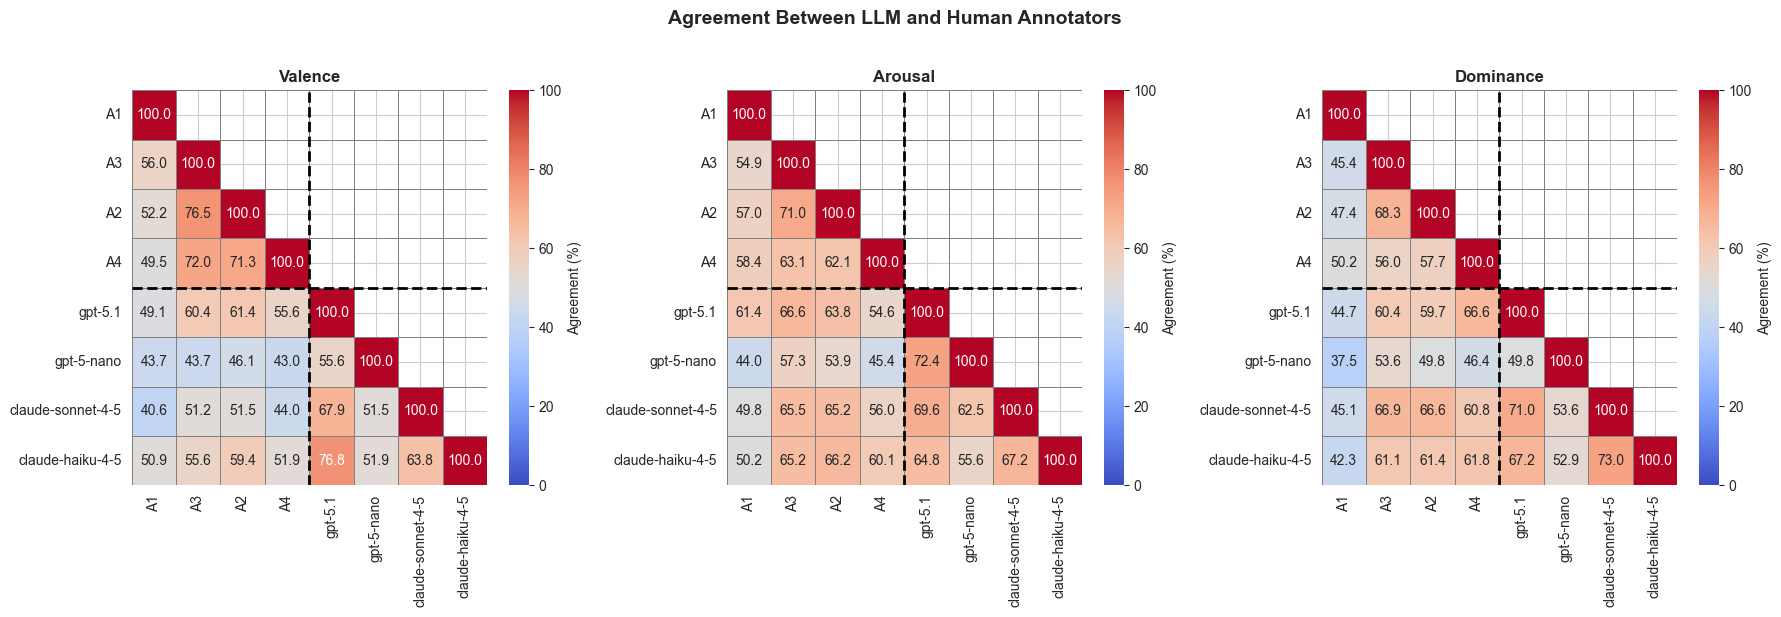

In [120]:
# Define human and LLM annotators, then create agreement heatmaps in one figure
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for idx, p in enumerate([p_val, p_aro, p_dom]):
    human_annotators = [col for col in p.pairwise_df.columns if col.startswith('A')]
    llm_annotators = [col for col in p.pairwise_df.columns if col.startswith('decision')]
    all_annotators = human_annotators + llm_annotators
    
    # Initialize a matrix to store agreement percentages
    agreement_matrix = np.zeros((len(all_annotators), len(all_annotators)))
    
    # Calculate agreement percentages
    for i, llm_col in enumerate(all_annotators):
        for j, human_col in enumerate(all_annotators):
            matches = (p.pairwise_df[llm_col] == p.pairwise_df[human_col]).sum()
            total = len(p.pairwise_df)
            agreement_pct = (matches / total) * 100
            agreement_matrix[i, j] = agreement_pct
    
    # Create clean labels by removing "decision_" prefix
    clean_labels = [col.replace('decision_', '') for col in all_annotators]
    
    # Create a DataFrame for better labeling
    agreement_df = pd.DataFrame(
        agreement_matrix,
        index=clean_labels,
        columns=clean_labels
    )
    
    # Create a mask for the upper triangle
    mask = np.triu(np.ones_like(agreement_df, dtype=bool), k=1)
    
    # Plot the heatmap on the current subplot
    ax = sns.heatmap(
        agreement_df,
        annot=True,
        fmt='.1f',
        cmap='coolwarm',
        vmin=0,
        vmax=100,
        cbar_kws={'label': 'Agreement (%)'},
        linewidths=0.5,
        linecolor='gray',
        mask=mask,
        ax=axes[idx]
    )
    
    # Add a bold dashed line to separate humans from LLMs
    num_humans = len(human_annotators)
    ax.axhline(y=num_humans, color='black', linewidth=2, linestyle='--')
    ax.axvline(x=num_humans, color='black', linewidth=2, linestyle='--')
    
    # Set title for this subplot
    ax.set_title(f'{p.target_concept.capitalize()}', fontsize=12, fontweight='bold')

plt.suptitle('Agreement Between LLM and Human Annotators', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# Unpaired AltTest

In [17]:
# Filter out rows where any column starting with 'A' has the value 'Tie'
valence_df_filtered = valence_df[~valence_df.filter(regex='^A').eq('Tie').any(axis=1)].reset_index(drop=True)
print(f"Number of unique items in valence after filtering ties: {len(pd.unique(valence_df_filtered[['item1', 'item2']].values.ravel()))}")
valence_df_filtered

Number of unique items in valence after filtering ties: 50


,item1,item2,text1,text2,A1,Notes_A1,A3,Notes_A3,A2,Notes_A2,A4,Notes_A4
0,112C-L015_1504_1606,Italy_4868_4942,"It can help purchase clothing, school supplies...",have a happy vacation that place looks fascina...,Text2,,Text2,,Text2,,Text2,
1,112C-L015_1504_1606,NYTnewswire1_3167_3223,"It can help purchase clothing, school supplies...",I'm very excited we'll be on the same team for...,Text2,,Text2,,Text2,,Text2,
2,112C-L015_1504_1606,Nathans_Bylichka_13402_13410,"It can help purchase clothing, school supplies...",“Bummer.,Text1,,Text1,,Text1,,Text1,
3,112C-L015_1504_1606,SemEval_185,"It can help purchase clothing, school supplies...",Squirrel jumps boy in park; rabies suspected,Text1,,Text1,,Text1,,Text1,
4,112C-L015_1504_1606,captured_moments_32287_32340,"It can help purchase clothing, school supplies...",I hold it against neither of you.,Text1,,Text1,,Text1,,Text1,
...,...,...,...,...,...,...,...,...,...,...,...,...
165,wsj_0120_2997_3087,SemEval_539,"""The thing that will really break this market ...",Two Muslim groups sue French newspaper Interna...,Text2,,Text1,,Text1,,Text2,
166,wsj_0120_2997_3087,SemEval_927,"""The thing that will really break this market ...",Why the smell of a man's armpit is a turn-on,Text2,,Text1,,Text1,,Text1,
167,wsj_0120_2997_3087,captured_moments_33672_33739,"""The thing that will really break this market ...","He nodded, repeated, ""I am sorry,"" then slippe...",Text2,,Text1,,Text1,,Text1,
168,wsj_0120_2997_3087,detroit_12015_12030,"""The thing that will really break this market ...","""Great Society""",Text2,,Text2,,Text2,,Text1,


In [18]:
# Filter out rows where any column starting with 'A' has the value 'Tie'
arousal_df_filtered = arousal_df[~arousal_df.filter(regex='^A').eq('Tie').any(axis=1)].reset_index(drop=True)
print(f"Number of unique items in arousal after filtering ties: {len(pd.unique(arousal_df_filtered[['item1', 'item2']].values.ravel()))}")
arousal_df_filtered

Number of unique items in arousal after filtering ties: 50


,item1,item2,text1,text2,A1,Notes_A1,A3,Notes_A3,A2,Notes_A2,A4,Notes_A4
0,112C-L015_1504_1606,Italy_4868_4942,"It can help purchase clothing, school supplies...",have a happy vacation that place looks fascina...,Text2,,Text2,,Text2,,Text2,
1,112C-L015_1504_1606,NYTnewswire1_3167_3223,"It can help purchase clothing, school supplies...",I'm very excited we'll be on the same team for...,Text2,,Text2,,Text2,,Text2,
2,112C-L015_1504_1606,NYTnewswire2_7491_7738,"It can help purchase clothing, school supplies...","Also on Feb. 12, a week before the ice dancing...",Text2,,Text2,,Text2,,Text2,
3,112C-L015_1504_1606,Nathans_Bylichka_13402_13410,"It can help purchase clothing, school supplies...",“Bummer.,Text1,,Text2,,Text2,,Text1,
4,112C-L015_1504_1606,SemEval_185,"It can help purchase clothing, school supplies...",Squirrel jumps boy in park; rabies suspected,Text2,,Text2,,Text2,,Text2,
...,...,...,...,...,...,...,...,...,...,...,...,...
199,wsj_0120_2997_3087,captured_moments_32287_32340,"""The thing that will really break this market ...",I hold it against neither of you.,Text2,,Text1,,Text1,,Text1,
200,wsj_0120_2997_3087,captured_moments_33672_33739,"""The thing that will really break this market ...","He nodded, repeated, ""I am sorry,"" then slippe...",Text1,,Text1,,Text1,,Text1,
201,wsj_0120_2997_3087,captured_moments_35401_35418,"""The thing that will really break this market ...","Now she will be.""",Text1,,Text1,,Text1,,Text1,
202,wsj_0120_2997_3087,detroit_12015_12030,"""The thing that will really break this market ...","""Great Society""",Text1,,Text1,,Text1,,Text1,


In [19]:
# Filter out rows where any column starting with 'A' has the value 'Tie'
dominance_df_filtered = dominance_df[~dominance_df.filter(regex='^A').eq('Tie').any(axis=1)].reset_index(drop=True)
print(f"Number of unique items in dominance after filtering ties: {len(pd.unique(dominance_df_filtered[['item1', 'item2']].values.ravel()))}")
dominance_df_filtered

Number of unique items in dominance after filtering ties: 50


,item1,item2,text1,text2,A1,Notes_A1,A3,Notes_A3,A2,Notes_A2,A4,Notes_A4
0,112C-L015_1504_1606,Italy_4868_4942,"It can help purchase clothing, school supplies...",have a happy vacation that place looks fascina...,Text2,,Text2,,Text1,,Text2,
1,112C-L015_1504_1606,NYTnewswire2_7491_7738,"It can help purchase clothing, school supplies...","Also on Feb. 12, a week before the ice dancing...",Text1,,Text2,,Text2,,Text2,
2,112C-L015_1504_1606,Nathans_Bylichka_13402_13410,"It can help purchase clothing, school supplies...",“Bummer.,Text2,,Text1,,Text1,,Text2,
3,112C-L015_1504_1606,Uprooted_Farming-on-Sand_313_353,"It can help purchase clothing, school supplies...",David DeWitt doesn't look like a farmer.,Text1,,Text1,,Text1,,Text2,
4,112C-L015_1504_1606,captured_moments_32287_32340,"It can help purchase clothing, school supplies...",I hold it against neither of you.,Text2,,Text2,,Text2,,Text2,
...,...,...,...,...,...,...,...,...,...,...,...,...
203,wsj_0120_2997_3087,captured_moments_32287_32340,"""The thing that will really break this market ...",I hold it against neither of you.,Text2,,Text1,,Text2,,Text2,
204,wsj_0120_2997_3087,captured_moments_33672_33739,"""The thing that will really break this market ...","He nodded, repeated, ""I am sorry,"" then slippe...",Text1,,Text1,,Text1,,Text1,
205,wsj_0120_2997_3087,captured_moments_35401_35418,"""The thing that will really break this market ...","Now she will be.""",Text1,,Text1,,Text2,,Text1,
206,wsj_0120_2997_3087,detroit_12015_12030,"""The thing that will really break this market ...","""Great Society""",Text1,,Text1,,Text1,,Text1,


## Build Unpaired Pairadigms

In [20]:
# Initialize Pairadigm objects
p_val_unpair = pdm.Pairadigm(
    data=valence_df_filtered,
    item_id_cols=['item1', 'item2'],
    item_text_cols=['text1', 'text2'],
    paired=True,
    annotated=True,
    annotator_cols=[col for col in valence_df_filtered.columns if col.startswith('A')],
    cgcot_prompts=val_prompts,
    model_name=["gpt-5.1", 
                'gpt-5-nano',
                "claude-sonnet-4-5",
                'claude-haiku-4-5'],
    api_key=[os.getenv('OPENAI_API_KEY'), 
             os.getenv('OPENAI_API_KEY'),
             os.getenv('ANTHROPIC_API_KEY'),
             os.getenv('ANTHROPIC_API_KEY')],
    base_url=["https://us.api.openai.com/v1", 
              "https://us.api.openai.com/v1",
              None, None],
    target_concept='valence'
)

p_aro_unpair = pdm.Pairadigm(
    data=arousal_df_filtered,
    item_id_cols=['item1', 'item2'],
    item_text_cols=['text1', 'text2'],
    paired=True,
    annotated=True,
    annotator_cols=[col for col in arousal_df_filtered.columns if col.startswith('A')],
    cgcot_prompts=aro_prompts,
    model_name=["gpt-5.1",
                'gpt-5-nano', 
                "claude-sonnet-4-5",
                'claude-haiku-4-5'],
    api_key=[os.getenv('OPENAI_API_KEY'), 
             os.getenv('OPENAI_API_KEY'),
             os.getenv('ANTHROPIC_API_KEY'),
             os.getenv('ANTHROPIC_API_KEY')],
    base_url=["https://us.api.openai.com/v1", 
              "https://us.api.openai.com/v1",
              None, None],
    target_concept='arousal'
)

p_dom_unpair = pdm.Pairadigm(
    data=dominance_df_filtered,
    item_id_cols=['item1', 'item2'],
    item_text_cols=['text1', 'text2'],
    paired=True,
    annotated=True,
    annotator_cols=[col for col in dominance_df_filtered.columns if col.startswith('A')],
    cgcot_prompts=dom_prompts,
    model_name=["gpt-5.1", 
                'gpt-5-nano',
                "claude-sonnet-4-5",
                'claude-haiku-4-5'],
    api_key=[os.getenv('OPENAI_API_KEY'), 
             os.getenv('OPENAI_API_KEY'),
             os.getenv('ANTHROPIC_API_KEY'),
             os.getenv('ANTHROPIC_API_KEY')],
    base_url=["https://us.api.openai.com/v1", 
              "https://us.api.openai.com/v1",
              None, None],
    target_concept='dominance'
)

In [21]:
for p in [p_val_unpair, p_aro_unpair, p_dom_unpair]:
    p.generate_breakdowns_from_paired()
# run time: 20 minutes

In [ ]:
for p in [p_val_unpair, p_aro_unpair, p_dom_unpair]:
    p.generate_pairwise_annotations(allow_ties=True)
# run time: 22 minutes

[gpt-5.1] Completed 50/170 comparisons
[gpt-5.1] Completed 100/170 comparisons
[gpt-5.1] Completed 150/170 comparisons
[gpt-5-nano] Completed 50/170 comparisons
[gpt-5-nano] Completed 100/170 comparisons
[gpt-5-nano] Completed 150/170 comparisons
[claude-sonnet-4-5] Completed 50/170 comparisons
[claude-sonnet-4-5] Completed 100/170 comparisons
[claude-sonnet-4-5] Completed 150/170 comparisons
[claude-haiku-4-5] Completed 50/170 comparisons
[claude-haiku-4-5] Completed 100/170 comparisons
[claude-haiku-4-5] Completed 150/170 comparisons
[gpt-5.1] Completed 50/204 comparisons
[gpt-5.1] Completed 100/204 comparisons
[gpt-5.1] Completed 150/204 comparisons
[gpt-5.1] Completed 200/204 comparisons
[gpt-5-nano] Completed 50/204 comparisons
[gpt-5-nano] Completed 100/204 comparisons
[gpt-5-nano] Completed 150/204 comparisons
[gpt-5-nano] Completed 200/204 comparisons
[claude-sonnet-4-5] Completed 50/204 comparisons
[claude-sonnet-4-5] Completed 100/204 comparisons
[claude-sonnet-4-5] Completed

In [24]:
today = pd.Timestamp.now().strftime('%m-%d-%y')

p_val_unpair.save(f'Results/pairadigms/untied_valence_pairadigm_{today}.pkl')
p_aro_unpair.save(f'Results/pairadigms/untied_arousal_pairadigm_{today}.pkl')
p_dom_unpair.save(f'Results/pairadigms/untied_dominance_pairadigm_{today}.pkl')

# Save pairwise results to CSV
for p in [p_val_unpair, p_aro_unpair, p_dom_unpair]:
    paired_results = p.pairwise_df
    paired_results.to_csv(f'Results/paired_results/untied_{p.target_concept}_paired_results_{today}.csv', index=False)

Pairadigm object saved successfully to: Results/pairadigms/untied_valence_pairadigm_12-19-25.pkl
Pairadigm object saved successfully to: Results/pairadigms/untied_arousal_pairadigm_12-19-25.pkl
Pairadigm object saved successfully to: Results/pairadigms/untied_dominance_pairadigm_12-19-25.pkl


## Validation

Testing 36 epsilon values from -0.1 to 0.25...
Testing all 4 LLM decision columns: ['decision_gpt-5.1', 'decision_gpt-5-nano', 'decision_claude-sonnet-4-5', 'decision_claude-haiku-4-5']
Using LLM decision column: decision_gpt-5.1
Using LLM decision column: decision_gpt-5.1

ALT-TEST RESULTS - GPT-5.1
Winning Rate (ω): 0.000
Advantage Probability: 0.595
Tested against 4 human annotators

Using LLM decision column: decision_gpt-5-nano

ALT-TEST RESULTS - GPT-5-NANO
Winning Rate (ω): 0.000
Advantage Probability: 0.600
Tested against 4 human annotators

Using LLM decision column: decision_claude-sonnet-4-5

ALT-TEST RESULTS - CLAUDE-SONNET-4-5
Winning Rate (ω): 0.000
Advantage Probability: 0.535
Tested against 4 human annotators

Using LLM decision column: decision_claude-haiku-4-5
[decision_claude-haiku-4-5] Dropped 1 instances with less than 2 annotators.

ALT-TEST RESULTS - CLAUDE-HAIKU-4-5
Winning Rate (ω): 0.000
Advantage Probability: 0.566
Tested against 4 human annotators

Testing a

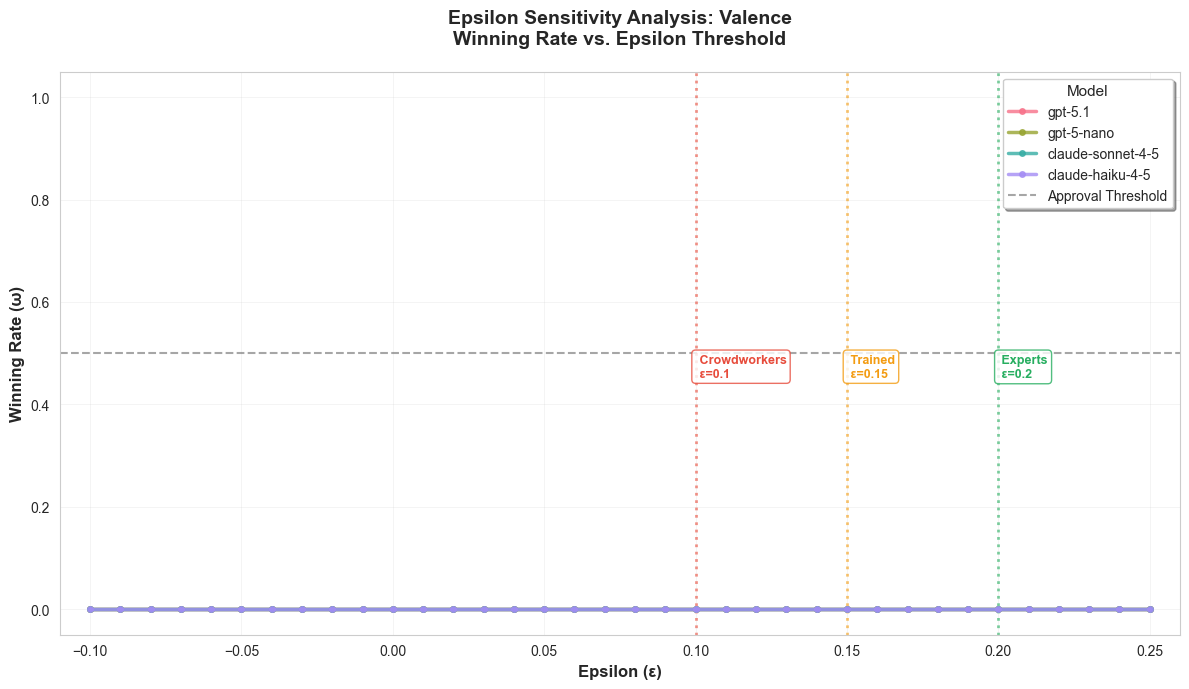

In [39]:
epsilon_val_untied = p_val_unpair.plot_epsilon_sensitivity(return_data=True)
epsilon_val_untied = pd.DataFrame(epsilon_val_untied[1])
epsilon_val_untied['construct'] = 'valence'

Testing 36 epsilon values from -0.1 to 0.25...
Testing all 4 LLM decision columns: ['decision_gpt-5.1', 'decision_gpt-5-nano', 'decision_claude-sonnet-4-5', 'decision_claude-haiku-4-5']
Using LLM decision column: decision_gpt-5.1
Using LLM decision column: decision_gpt-5.1

ALT-TEST RESULTS - GPT-5.1
Winning Rate (ω): 0.000
Advantage Probability: 0.885
Tested against 4 human annotators

Using LLM decision column: decision_gpt-5-nano

ALT-TEST RESULTS - GPT-5-NANO
Winning Rate (ω): 0.000
Advantage Probability: 0.820
Tested against 4 human annotators

Using LLM decision column: decision_claude-sonnet-4-5

ALT-TEST RESULTS - CLAUDE-SONNET-4-5
Winning Rate (ω): 0.000
Advantage Probability: 0.840
Tested against 4 human annotators

Using LLM decision column: decision_claude-haiku-4-5

ALT-TEST RESULTS - CLAUDE-HAIKU-4-5
Winning Rate (ω): 0.000
Advantage Probability: 0.765
Tested against 4 human annotators

Testing all 4 LLM decision columns: ['decision_gpt-5.1', 'decision_gpt-5-nano', 'decis

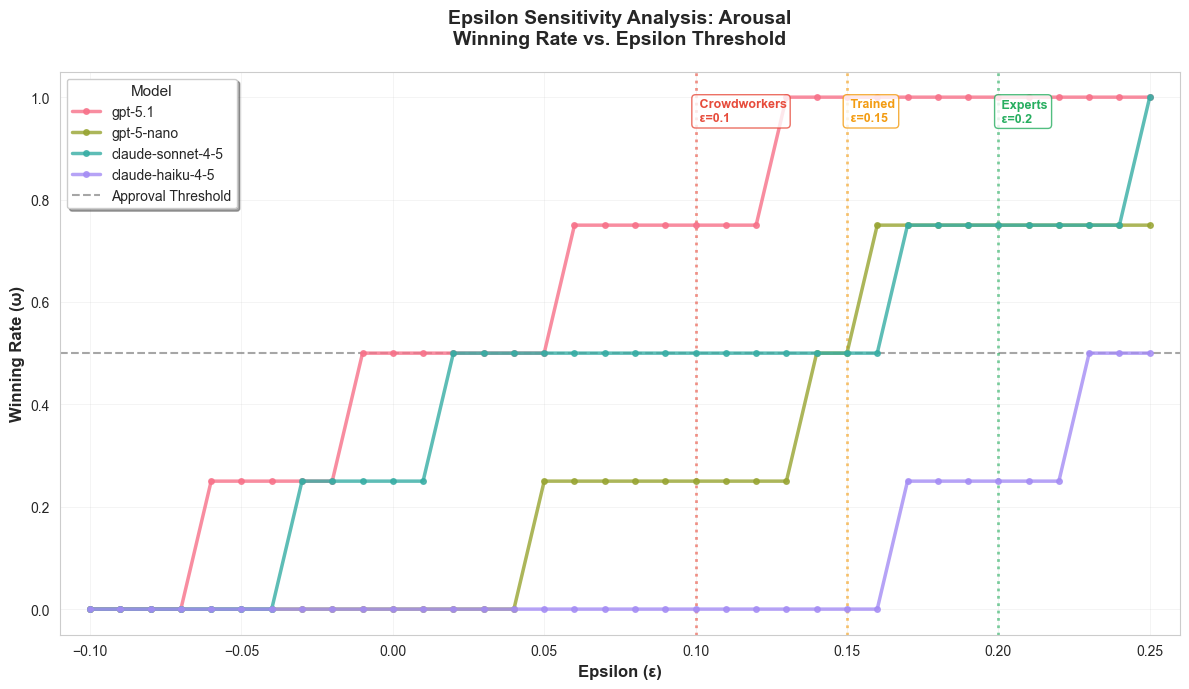

In [40]:
epsilon_aro_untied = p_aro_unpair.plot_epsilon_sensitivity(return_data=True)
epsilon_aro_untied = pd.DataFrame(epsilon_aro_untied[1])
epsilon_aro_untied['construct'] = 'arousal'

Testing 36 epsilon values from -0.1 to 0.25...
Testing all 4 LLM decision columns: ['decision_gpt-5.1', 'decision_gpt-5-nano', 'decision_claude-sonnet-4-5', 'decision_claude-haiku-4-5']
Using LLM decision column: decision_gpt-5.1
Using LLM decision column: decision_gpt-5.1

ALT-TEST RESULTS - GPT-5.1
Winning Rate (ω): 0.000
Advantage Probability: 0.850
Tested against 4 human annotators

Using LLM decision column: decision_gpt-5-nano

ALT-TEST RESULTS - GPT-5-NANO
Winning Rate (ω): 0.000
Advantage Probability: 0.830
Tested against 4 human annotators

Using LLM decision column: decision_claude-sonnet-4-5

ALT-TEST RESULTS - CLAUDE-SONNET-4-5
Winning Rate (ω): 0.000
Advantage Probability: 0.880
Tested against 4 human annotators

Using LLM decision column: decision_claude-haiku-4-5

ALT-TEST RESULTS - CLAUDE-HAIKU-4-5
Winning Rate (ω): 0.000
Advantage Probability: 0.850
Tested against 4 human annotators

Testing all 4 LLM decision columns: ['decision_gpt-5.1', 'decision_gpt-5-nano', 'decis

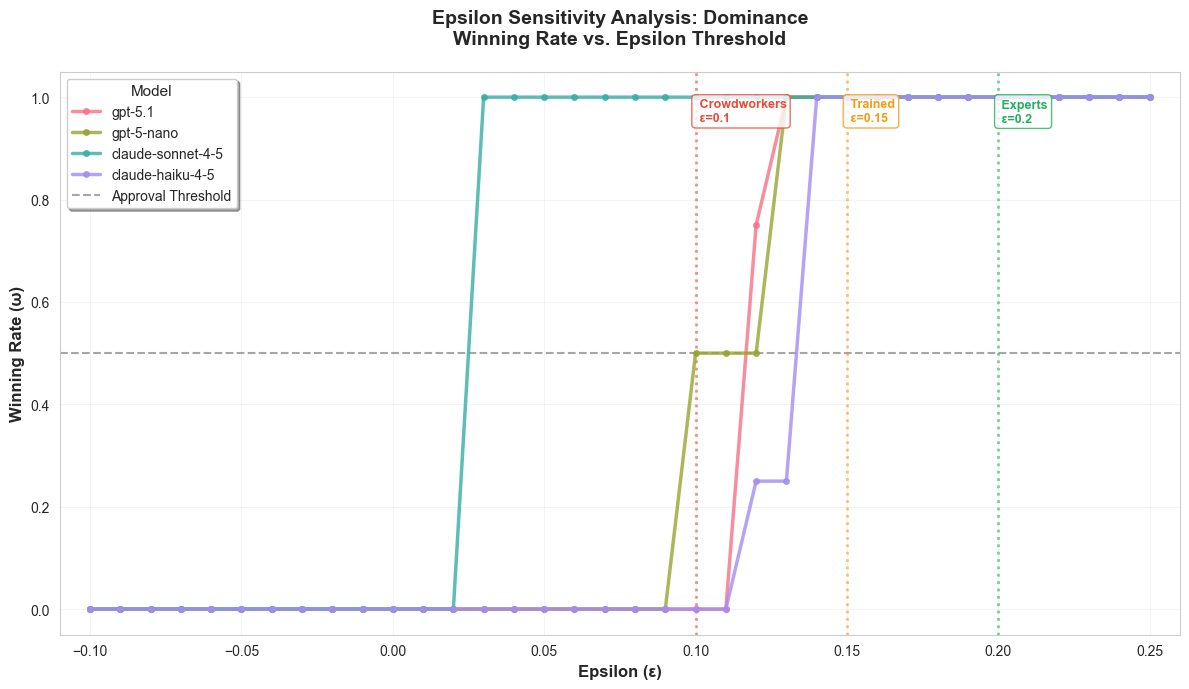

In [41]:
epsilon_dom_untied = p_dom_unpair.plot_epsilon_sensitivity(return_data=True)
epsilon_dom_untied = pd.DataFrame(epsilon_dom_untied[1])
epsilon_dom_untied['construct'] = 'dominance'

In [ ]:
epsilon_df_untied = pd.concat([epsilon_val_untied, epsilon_aro_untied, epsilon_dom_untied], axis=0)
epsilon_df_untied

,epsilon,winning_rate,advantage_prob,model,construct
0,-0.10,0.0,0.595000,gpt-5.1,valence
1,-0.10,0.0,0.600000,gpt-5-nano,valence
2,-0.10,0.0,0.535000,claude-sonnet-4-5,valence
3,-0.10,0.0,0.566327,claude-haiku-4-5,valence
4,-0.09,0.0,0.595000,gpt-5.1,valence
...,...,...,...,...,...
139,0.24,1.0,0.850000,claude-haiku-4-5,dominance
140,0.25,1.0,0.850000,gpt-5.1,dominance
141,0.25,1.0,0.830000,gpt-5-nano,dominance
142,0.25,1.0,0.880000,claude-sonnet-4-5,dominance


In [43]:
# Get the advantage probability for each model and construct
ad_prob_df_untied = epsilon_df_untied[['advantage_prob', 'model', 'construct']].drop_duplicates()
ad_prob_df_untied

,advantage_prob,model,construct
0,0.595000,gpt-5.1,valence
1,0.600000,gpt-5-nano,valence
2,0.535000,claude-sonnet-4-5,valence
3,0.566327,claude-haiku-4-5,valence
0,0.885000,gpt-5.1,arousal
1,0.820000,gpt-5-nano,arousal
2,0.840000,claude-sonnet-4-5,arousal
3,0.765000,claude-haiku-4-5,arousal
0,0.850000,gpt-5.1,dominance
1,0.830000,gpt-5-nano,dominance


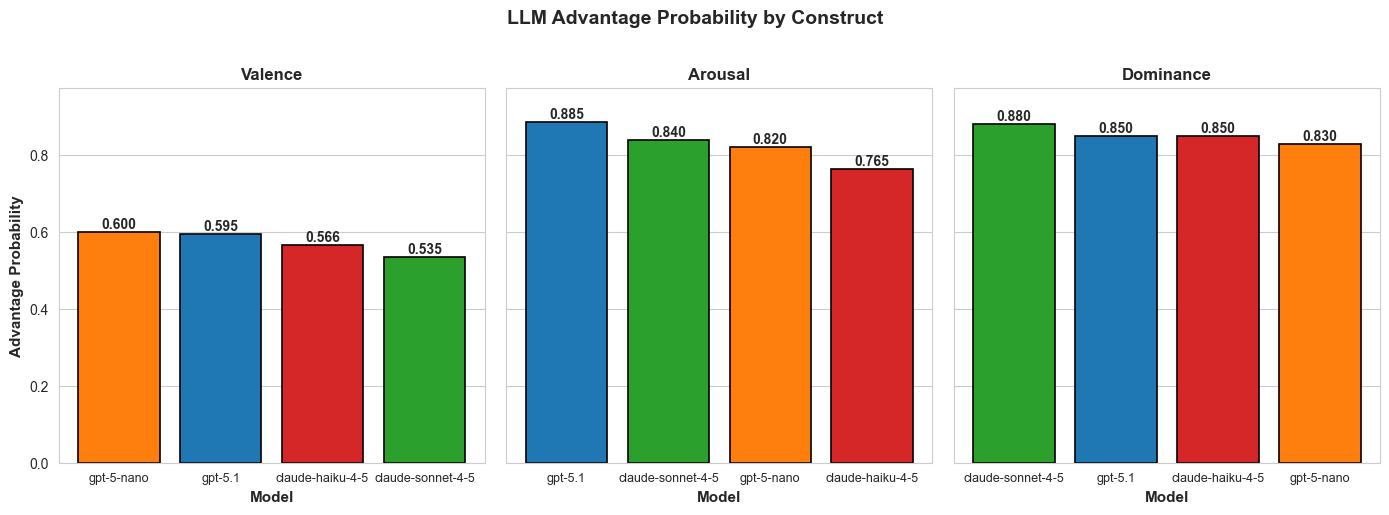

In [45]:
import matplotlib.pyplot as plt
import seaborn as sns

# Define a consistent color palette for models
model_colors = {
    'gpt-5.1': '#1f77b4',
    'gpt-5-nano': '#ff7f0e',
    'claude-sonnet-4-5': '#2ca02c',
    'claude-haiku-4-5': '#d62728'
}

# Create faceted bar plot
fig, axes = plt.subplots(1, 3, figsize=(14, 5), sharey=True)
constructs = ['valence', 'arousal', 'dominance']

for idx, (ax, construct) in enumerate(zip(axes, constructs)):
    # Filter data for this construct
    construct_data = ad_prob_df_untied[ad_prob_df_untied['construct'] == construct].sort_values('advantage_prob', ascending=False)
    
    # Map colors based on model
    colors = [model_colors.get(model, '#808080') for model in construct_data['model']]
    
    # Create bar plot
    bars = ax.bar(construct_data['model'], construct_data['advantage_prob'], 
                   color=colors, 
                   edgecolor='black', linewidth=1.2)
    
    # Add value labels on bars
    for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height,
                f'{height:.3f}',
                ha='center', va='bottom', fontsize=10, fontweight='bold')
    
    # Formatting
    ax.set_title(construct.capitalize(), fontsize=12, fontweight='bold')
    ax.set_xlabel('Model', fontsize=11, fontweight='bold')
    if idx == 0:
        ax.set_ylabel('Advantage Probability', fontsize=11, fontweight='bold')
    ax.set_ylim(0, max(ad_prob_df_untied['advantage_prob']) * 1.1)
    ax.tick_params(axis='x', 
                   #rotation=45, 
                   labelsize=9)
    ax.grid(axis='x', alpha=0, linestyle='--')
    

plt.suptitle('LLM Advantage Probability by Construct', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()